# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses.

Bộ dữ liệu sử dụng: [MNIST dataset](https://git-disl.github.io/GTDLBench/datasets/mnist_datasets/) (bài 1) và [VinaFood21 dataset](https://arxiv.org/abs/2108.02929) (các bài còn lại).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

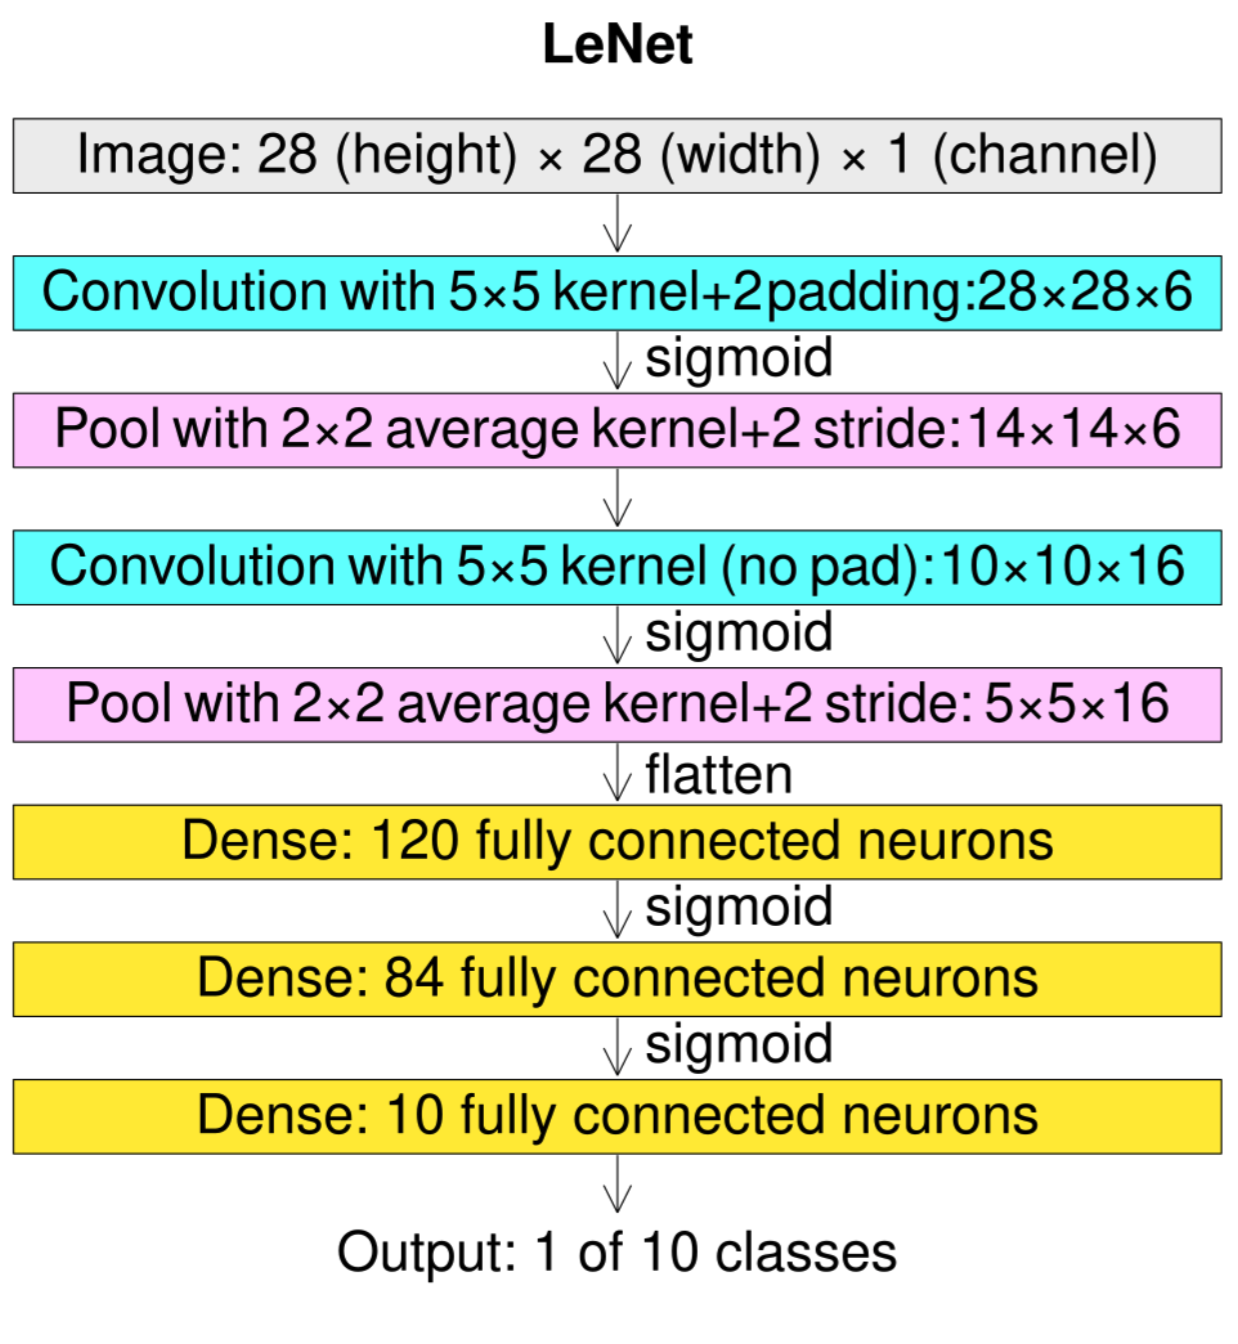

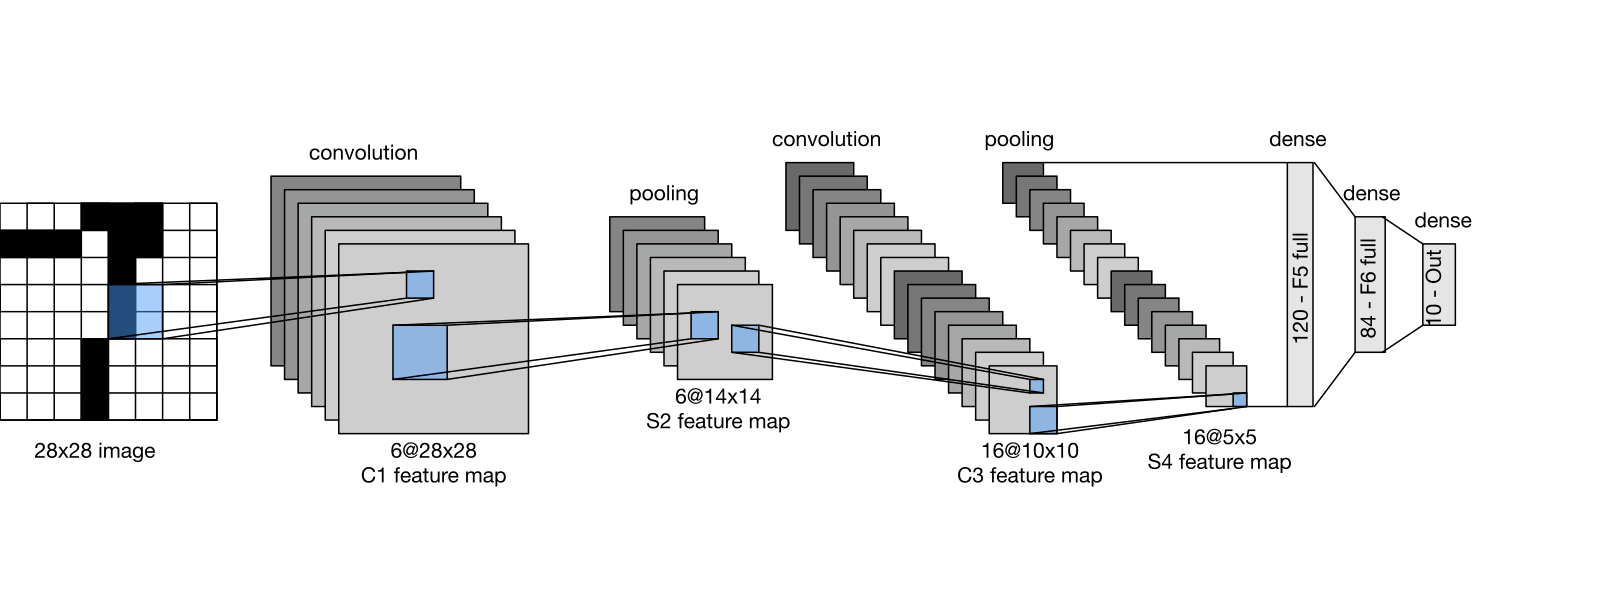

Notebook chạy được trên CPU local hoặc GPU. Trên Kaggle, thêm bộ code và dữ liệu vào Input, bật Internet để tải pretrained ResNet50. Kết quả lưu trong `/kaggle/working/checkpoints`. `retrain = True` để huấn luyện lại; đổi thành `False` để dùng trọng số đã lưu.

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

input_root = Path("/kaggle/input")
candidates = [Path.cwd(), Path.cwd() / "Thực Hành 2", Path("/content/Thực Hành 2")]
if input_root.exists():
    candidates += [p.parent.parent for p in input_root.glob("**/modeling/lenet.py")]
project_dir = next((p for p in candidates if (p / "modeling/lenet.py").exists()), None)
if project_dir is None:
    raise FileNotFoundError("Cần upload thư mục code gồm modeling, Load_data, support và metrics.py")
sys.path.insert(0, str(project_dir))

from Load_data import MNISTDataset, ImageDataset, VinaFoodDataset
from modeling import LeNet, GoogLeNet, ResNet18, ResNet50
from support.trainer import fit, predict
from metrics import evaluate
from support.visualization import plot_history, plot_scores, plot_confusion, plot_distribution

data_dir = project_dir / "data"
mnist_dir = data_dir
food_dir = data_dir / "VinaFood21"
if input_root.exists():
    mnist_dir = next((p.parent for p in input_root.glob("**/train-images-idx3-ubyte")), mnist_dir)
    food_dir = next((p.parent for p in input_root.glob("**/train") if (p.parent / "test").is_dir() and (p / "banh-can").is_dir()), food_dir)
output_root = Path("/kaggle/working/checkpoints") if input_root.exists() else project_dir / "checkpoints"
torch.manual_seed(42)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = device.type == "cuda"
print(f"Device: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))
batch_size = 64
epochs = 10
learning_rate = 0.001
retrain = False
x_train, y_train, x_test, y_test = MNISTDataset(mnist_dir).load()
print(f"MNIST - Train: {len(y_train)} | Test: {len(y_test)}")

Device: cuda
Tesla T4
MNIST - Train: 60000 | Test: 10000


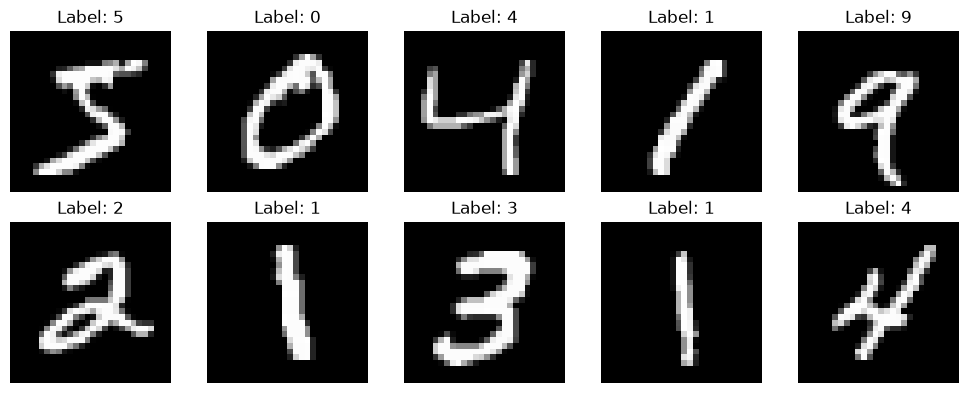

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for index, ax in enumerate(axes.flat):
    ax.imshow(x_train[index].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {y_train[index]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
lenet = LeNet().to(device)
train_loader = DataLoader(ImageDataset(x_train, y_train, image_size=28), batch_size=batch_size, shuffle=True, pin_memory=device.type == "cuda")
test_loader = DataLoader(ImageDataset(x_test, y_test, image_size=28), batch_size=batch_size, shuffle=False, pin_memory=device.type == "cuda")
print(lenet)
print(f"Parameters: {sum(p.numel() for p in lenet.parameters()):,}")

LeNet(
  (conv_1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv_2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc_1): Linear(in_features=400, out_features=120, bias=True)
  (fc_2): Linear(in_features=120, out_features=84, bias=True)
  (output): Linear(in_features=84, out_features=10, bias=True)
)
Parameters: 61,706


In [5]:
output_dir = output_root / "bai1"
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint = output_dir / "lenet.pth"
result_path = output_dir / "results.json"
if not retrain and checkpoint.exists() and result_path.exists():
    lenet.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    history_lenet = json.loads(result_path.read_text(encoding="utf-8"))["history"]
    print("Loaded saved model and training history")
    for epoch, item in enumerate(history_lenet, 1):
        print(f"Epoch {epoch}/{len(history_lenet)} | loss: {item['loss']:.4f} | accuracy: {item['accuracy']:.4f}")
else:
    history_lenet = fit(lenet, train_loader, device, epochs=epochs, learning_rate=learning_rate)
    torch.save(lenet.state_dict(), checkpoint)
predictions_lenet = predict(lenet, test_loader, device)
scores_lenet = evaluate(y_test, predictions_lenet)
results = {"config": {"epochs": len(history_lenet), "batch_size": batch_size, "learning_rate": learning_rate, "image_size": 28, "seed": 42, "device": str(device), "mixed_precision": device.type == "cuda"}, "history": history_lenet, "test_metrics": scores_lenet}
result_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"Saved: {output_dir}")


Epoch 1/10 | loss: 1.0973 | accuracy: 0.6377
Epoch 2/10 | loss: 0.2715 | accuracy: 0.9188
Epoch 3/10 | loss: 0.1722 | accuracy: 0.9476
Epoch 4/10 | loss: 0.1267 | accuracy: 0.9624
Epoch 5/10 | loss: 0.1026 | accuracy: 0.9689
Epoch 6/10 | loss: 0.0859 | accuracy: 0.9739
Epoch 7/10 | loss: 0.0735 | accuracy: 0.9778
Epoch 8/10 | loss: 0.0658 | accuracy: 0.9799
Epoch 9/10 | loss: 0.0590 | accuracy: 0.9818
Epoch 10/10 | loss: 0.0536 | accuracy: 0.9838
Accuracy: 0.9827
Class                 Precision  Recall  F1-score
0                     0.9799     0.9929  0.9863
1                     0.9912     0.9947  0.9930
2                     0.9873     0.9826  0.9849
3                     0.9889     0.9713  0.9800
4                     0.9876     0.9756  0.9816
5                     0.9705     0.9944  0.9823
6                     0.9884     0.9823  0.9853
7                     0.9862     0.9708  0.9784
8                     0.9825     0.9815  0.9820
9                     0.9630     0.9812  0.9720
Pr

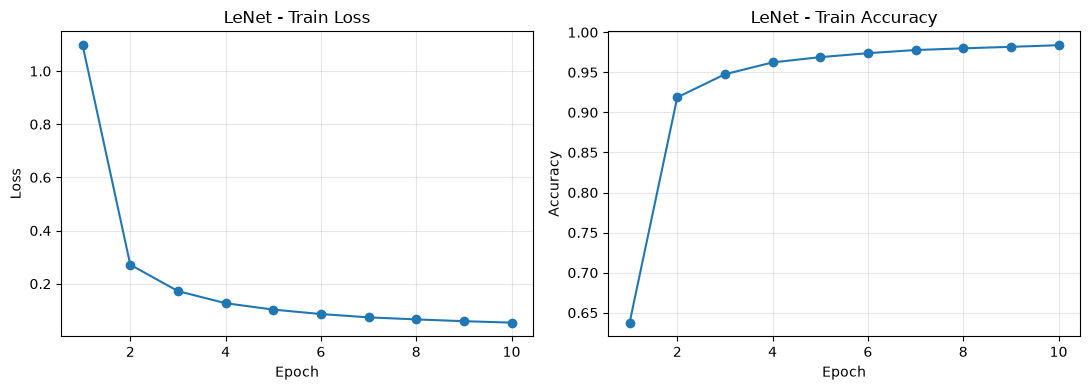

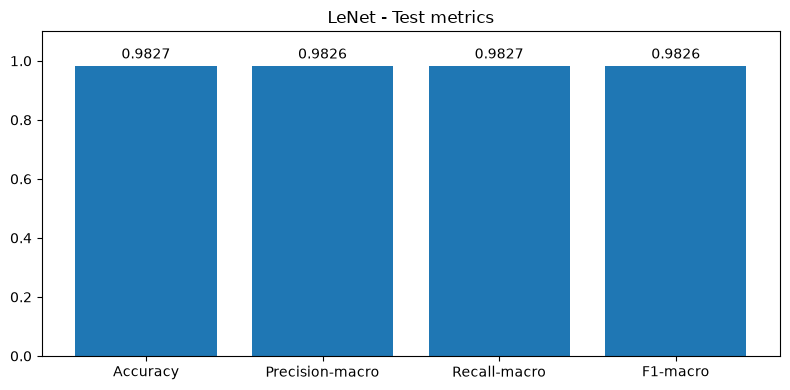

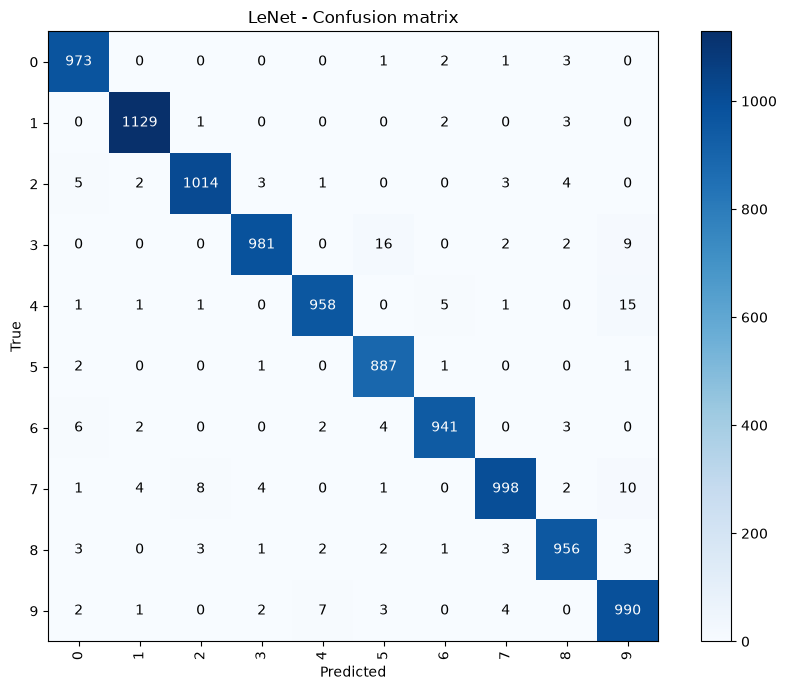

In [6]:
plot_history(history_lenet, "LeNet")
plot_scores(scores_lenet, "LeNet")
plot_confusion(y_test, predictions_lenet, "LeNet")

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer). Lưu ý lớp Convolution đầu tiên có padding là 3, các lớp Max Pooling đều bật chế độ ceil_mode (`ceil_mode=True`).

**Inception Blocks**

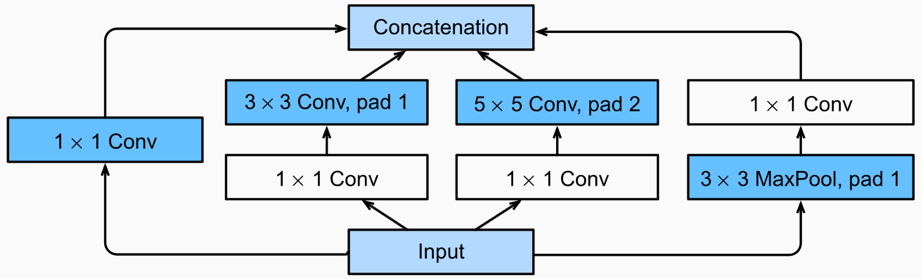

**GoogLeNet (Multi-branch Network)**

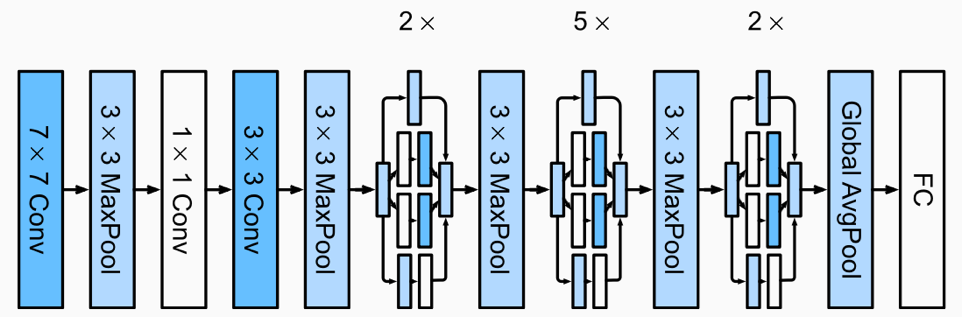

**GoogLeNet Parameters**

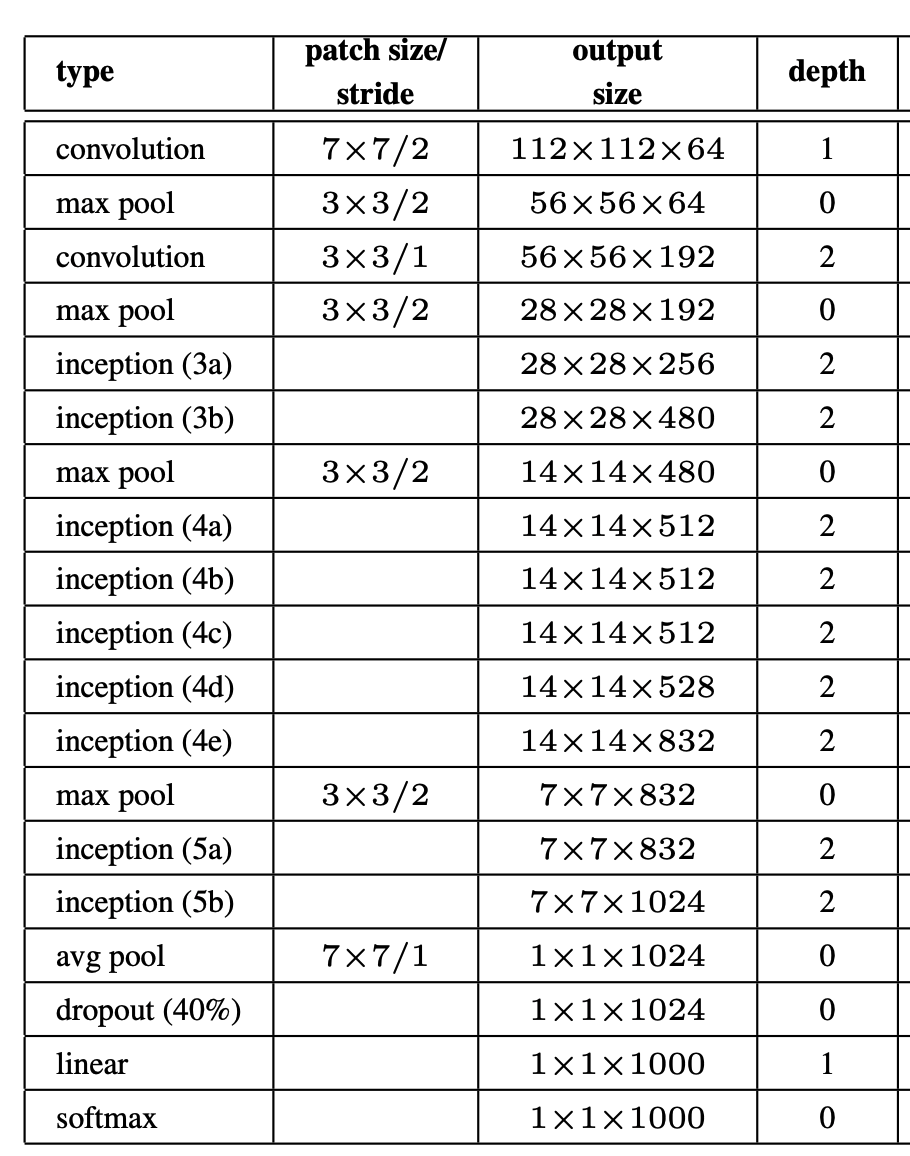

Ảnh MNIST được resize thành 64×64 để đi qua đủ các lớp pooling. Conv đầu có padding 3; tất cả MaxPool bật ceil_mode=True. Chạy các ô bên dưới để huấn luyện bằng Adam và hiển thị kết quả. Huấn luyện GoogLeNet trên CPU có thể mất nhiều thời gian.

In [7]:
googlenet = GoogLeNet().to(device)
train_loader = DataLoader(ImageDataset(x_train, y_train, image_size=64), batch_size=batch_size, shuffle=True, pin_memory=device.type == "cuda")
test_loader = DataLoader(ImageDataset(x_test, y_test, image_size=64), batch_size=batch_size, shuffle=False, pin_memory=device.type == "cuda")
print(googlenet)
print(f"Parameters: {sum(p.numel() for p in googlenet.parameters()):,}")

GoogLeNet(
  (block_1): Sequential(
    (0): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
  )
  (block_2): Sequential(
    (0): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
  )
  (block_3): Sequential(
    (0): Inception(
      (branch_1): Sequential(
        (0): Conv2d(192, 64, kernel_size=(1, 1), stride=(1, 1))
        (1): ReLU()
      )
      (branch_2): Sequential(
        (0): Conv2d(192, 96, kernel_size=(1, 1), stride=(1, 1))
        (1): ReLU()
        (2): Conv2d(96, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU()
      )
      (branch_3): Sequential(
        (0): Conv2d(192, 16, kernel_size=(1, 1), stride=(1, 1))
        (1): ReLU()
     

In [8]:
output_dir = output_root / "bai2"
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint = output_dir / "googlenet.pth"
result_path = output_dir / "results.json"
if not retrain and checkpoint.exists() and result_path.exists():
    googlenet.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    history_googlenet = json.loads(result_path.read_text(encoding="utf-8"))["history"]
    print("Loaded saved model and training history")
    for epoch, item in enumerate(history_googlenet, 1):
        print(f"Epoch {epoch}/{len(history_googlenet)} | loss: {item['loss']:.4f} | accuracy: {item['accuracy']:.4f}")
else:
    history_googlenet = fit(googlenet, train_loader, device, epochs=epochs, learning_rate=learning_rate)
    torch.save(googlenet.state_dict(), checkpoint)
predictions_googlenet = predict(googlenet, test_loader, device)
scores_googlenet = evaluate(y_test, predictions_googlenet)
results = {"config": {"epochs": len(history_googlenet), "batch_size": batch_size, "learning_rate": learning_rate, "image_size": 64, "seed": 42, "device": str(device), "mixed_precision": device.type == "cuda"}, "history": history_googlenet, "test_metrics": scores_googlenet}
result_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"Saved: {output_dir}")


Epoch 1/10 | loss: 0.4670 | accuracy: 0.8426
Epoch 2/10 | loss: 0.0697 | accuracy: 0.9805
Epoch 3/10 | loss: 0.0534 | accuracy: 0.9855
Epoch 4/10 | loss: 0.0426 | accuracy: 0.9880
Epoch 5/10 | loss: 0.0389 | accuracy: 0.9891
Epoch 6/10 | loss: 0.0338 | accuracy: 0.9905
Epoch 7/10 | loss: 0.0282 | accuracy: 0.9921
Epoch 8/10 | loss: 0.0283 | accuracy: 0.9921
Epoch 9/10 | loss: 0.0247 | accuracy: 0.9930
Epoch 10/10 | loss: 0.0196 | accuracy: 0.9944
Accuracy: 0.9893
Class                 Precision  Recall  F1-score
0                     0.9979     0.9898  0.9939
1                     0.9947     0.9982  0.9965
2                     0.9727     1.0000  0.9861
3                     0.9970     0.9881  0.9925
4                     0.9979     0.9847  0.9913
5                     0.9812     0.9955  0.9883
6                     0.9957     0.9697  0.9825
7                     0.9893     0.9932  0.9913
8                     0.9856     0.9825  0.9841
9                     0.9813     0.9891  0.9852
Pr

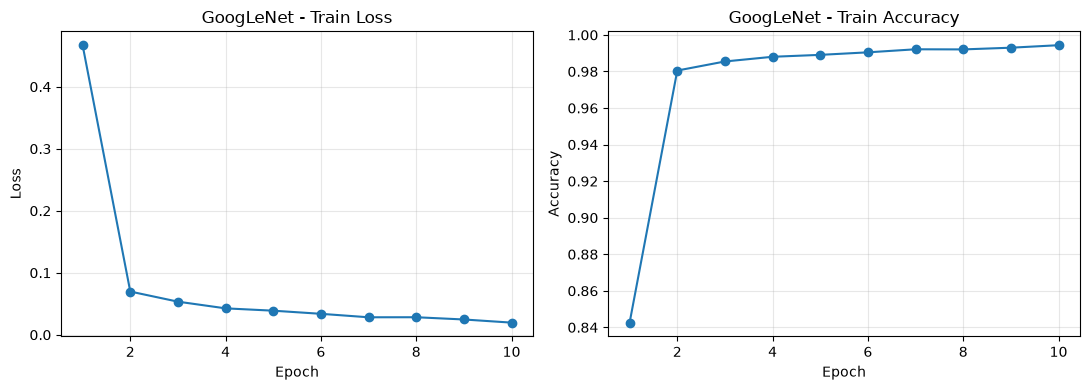

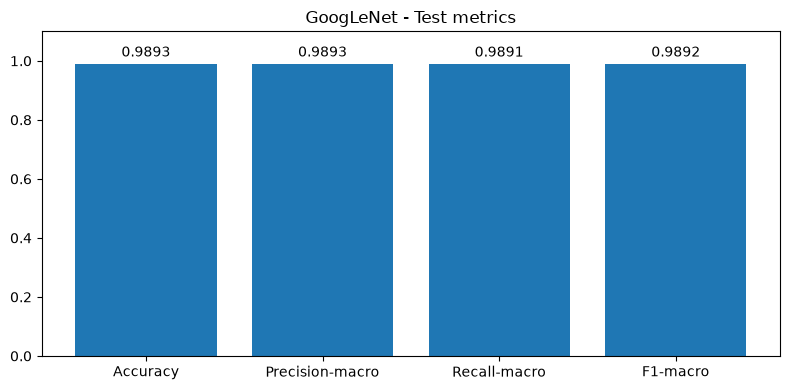

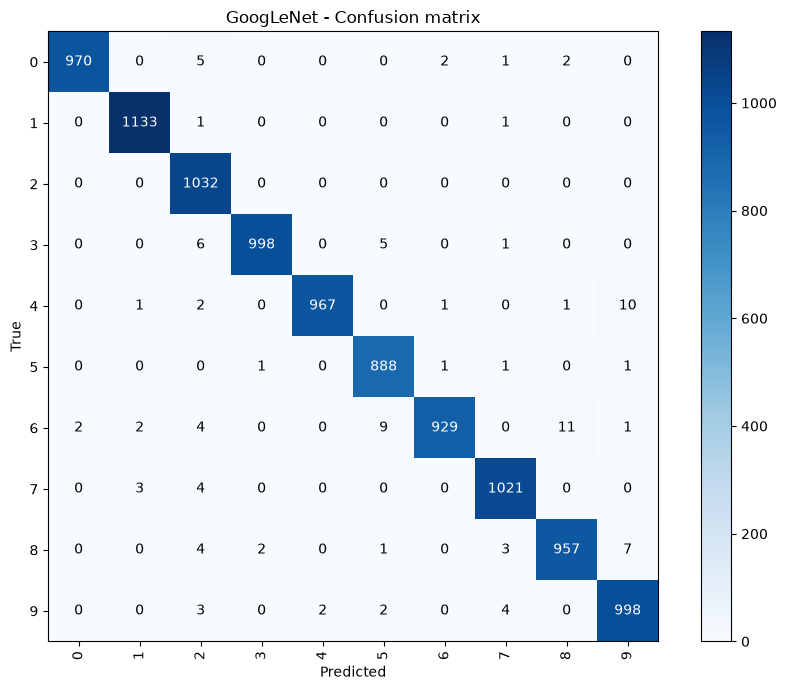

In [9]:
plot_history(history_googlenet, "GoogLeNet")
plot_scores(scores_googlenet, "GoogLeNet")
plot_confusion(y_test, predictions_googlenet, "GoogLeNet")

### Bài 3: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer). Lưu ý, giữa các block Residual-Connection có một lớp Max Pooling (kernel = 3, stride = 2, paddding = 0)

**ResNet Block**

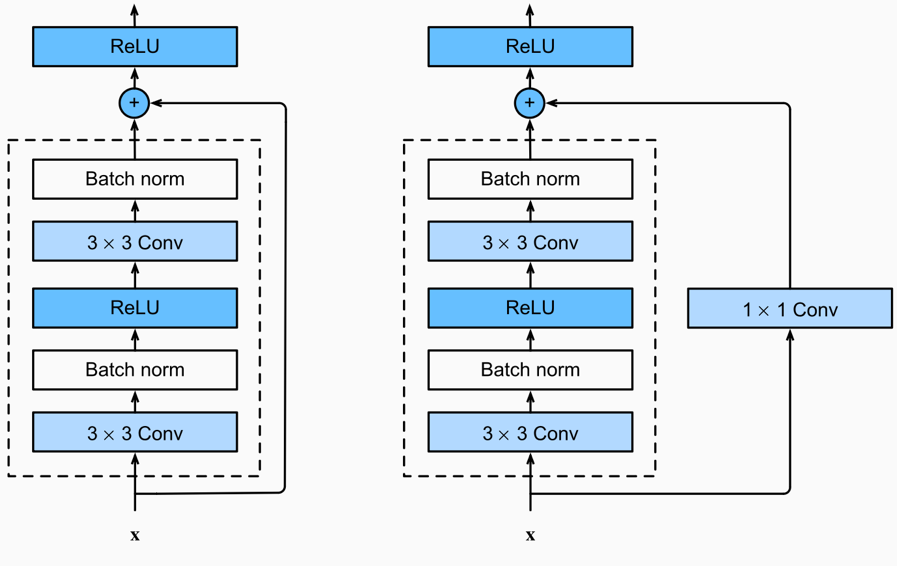

**ResNet**

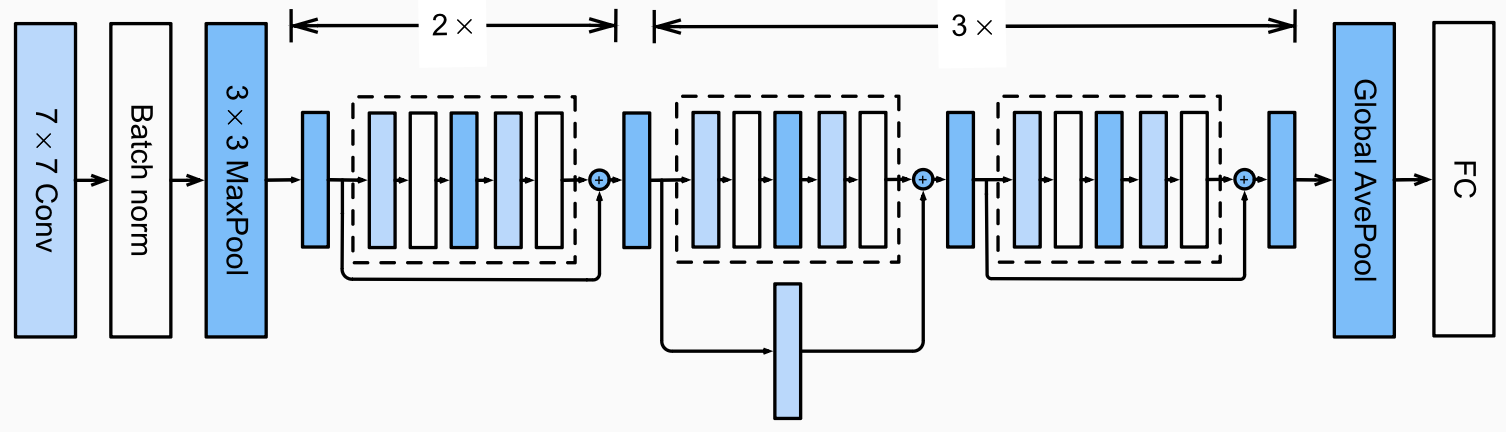

**ResNet-18 Parameter**
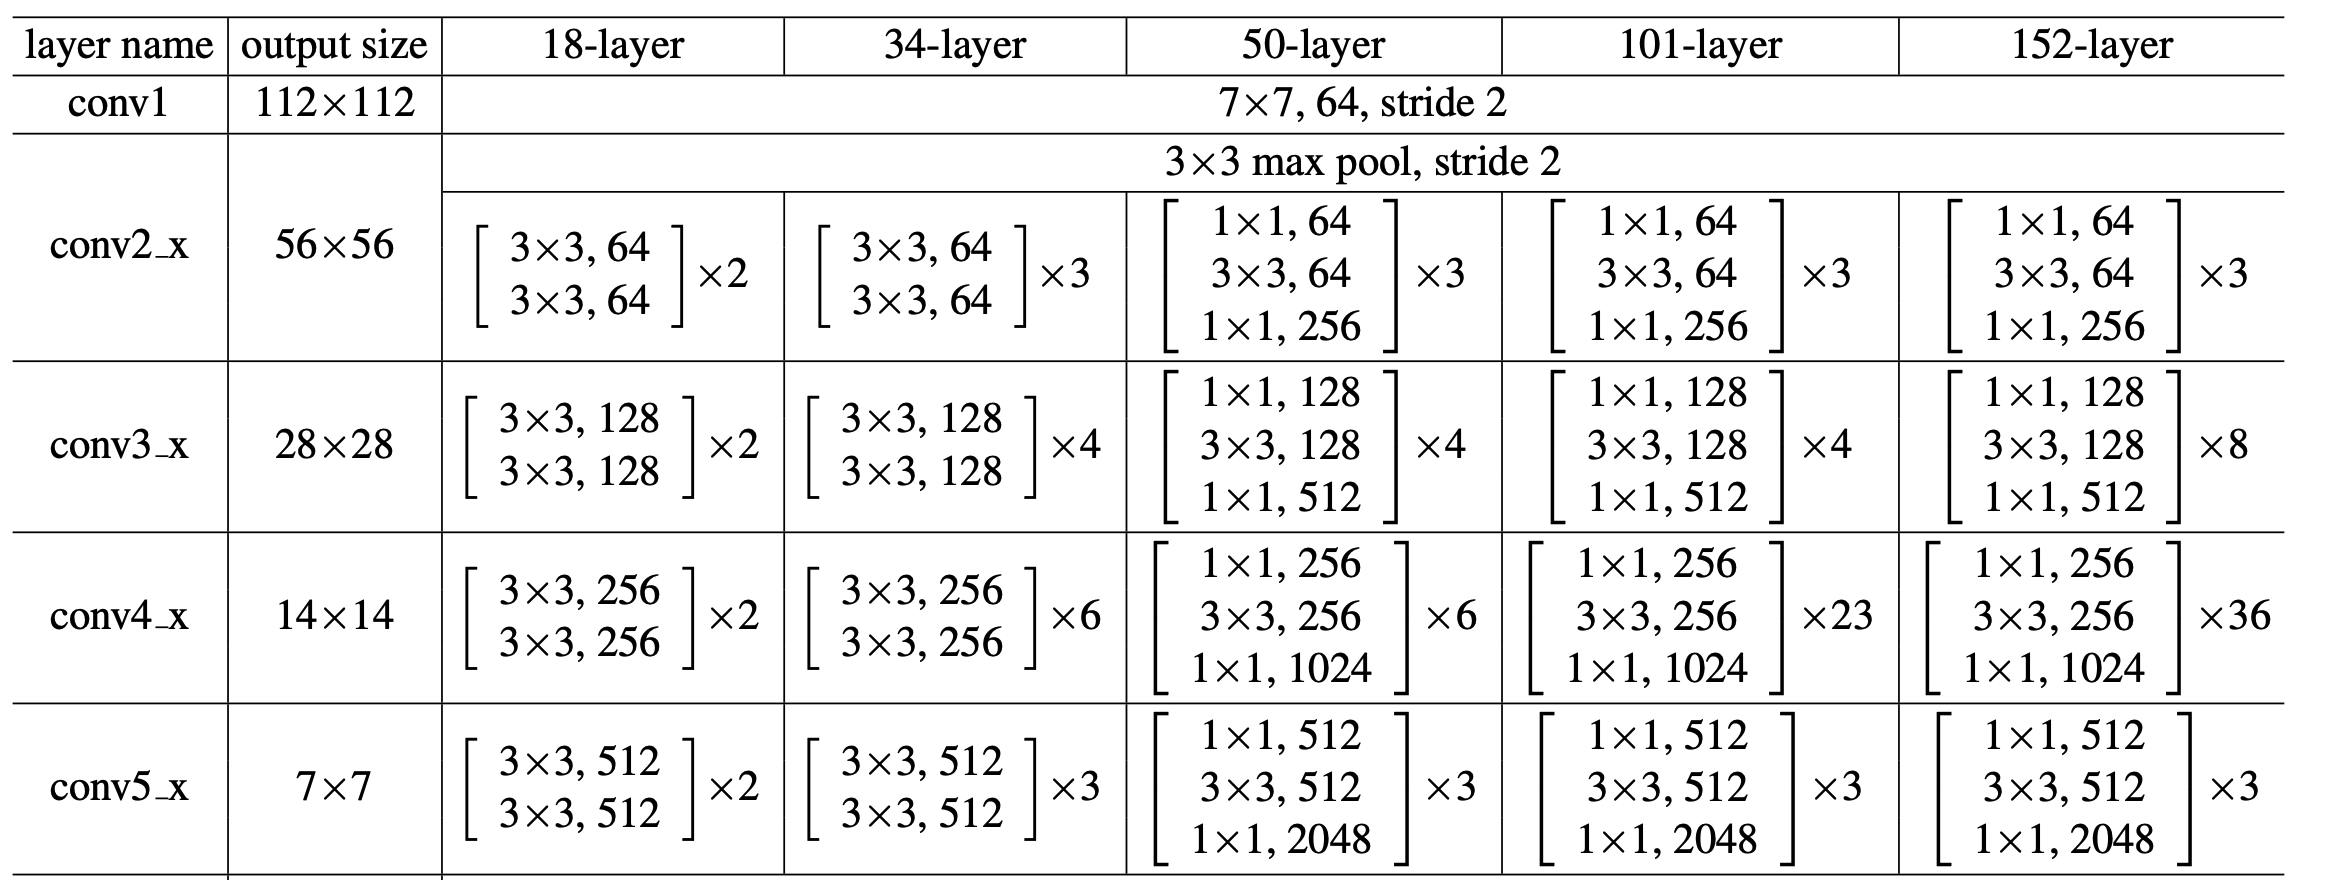

ResNet-18 gồm 4 nhóm, mỗi nhóm 2 residual block. Giữa các nhóm dùng MaxPool 3×3, stride 2, padding 0 thay cho convolution stride 2. Ảnh RGB được crop 224×224, chuẩn hóa và augment trên tập train; tập test chỉ dùng để đánh giá sau huấn luyện.

VinaFood21 - Train: 10044 | Test: 6682 | Classes: 21
['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']


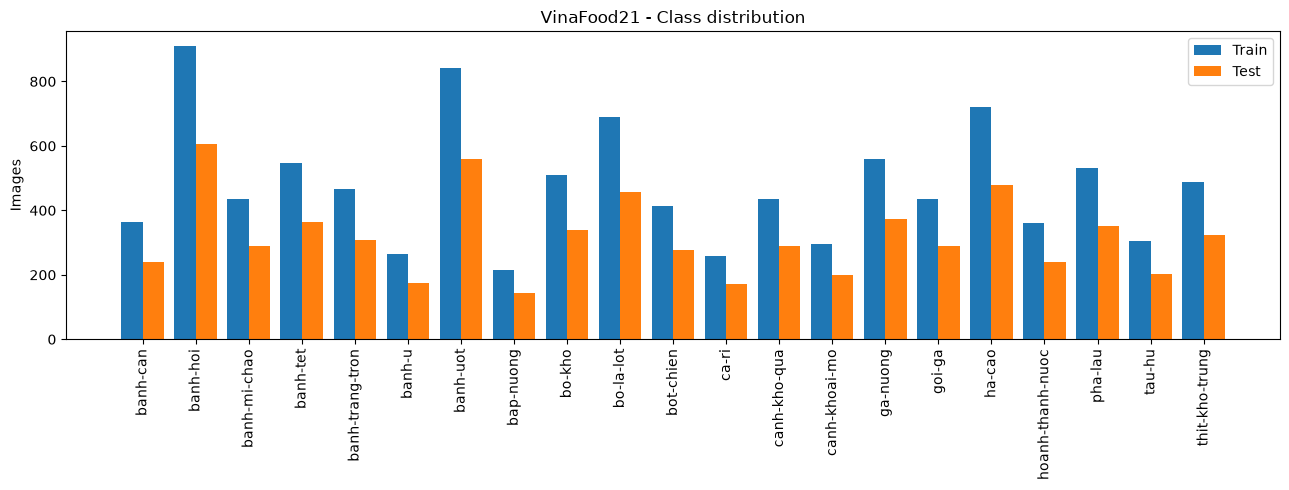

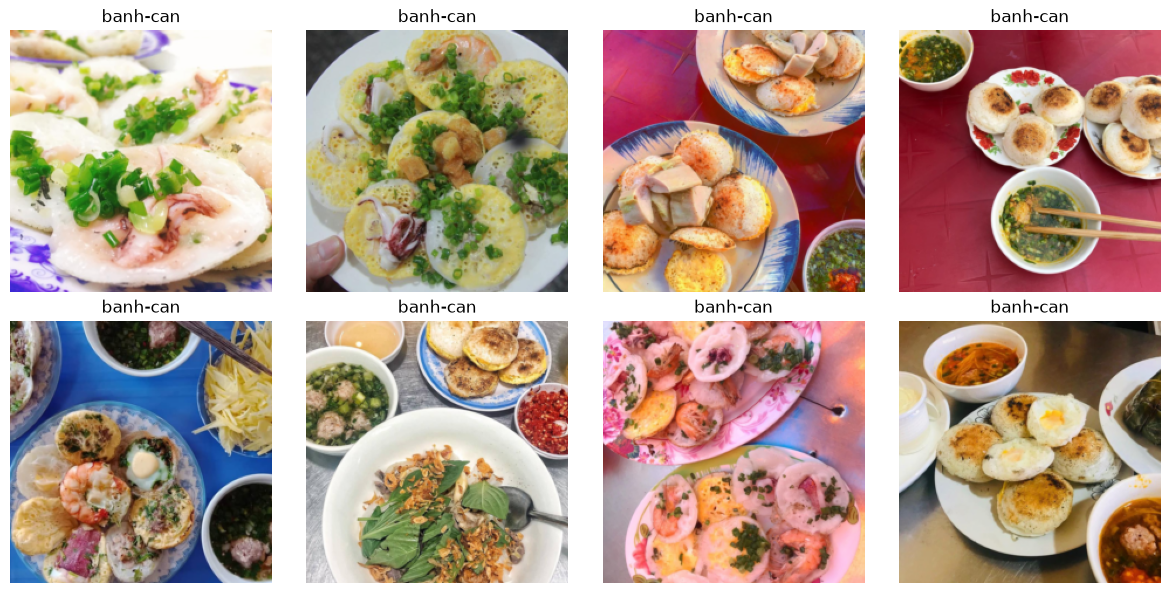

In [10]:
food_train, food_test = VinaFoodDataset(food_dir).load()
class_names = food_train.classes
print(f"VinaFood21 - Train: {len(food_train)} | Test: {len(food_test)} | Classes: {len(class_names)}")
print(class_names)
plot_distribution(food_train.targets, food_test.targets, class_names)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for index, ax in enumerate(axes.flat):
    image, label = food_test[index]
    image = image.permute(1, 2, 0).numpy() * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [11]:
resnet18 = ResNet18(num_classes=21).to(device)
food_batch_size = 32
train_loader = DataLoader(food_train, batch_size=food_batch_size, shuffle=True, pin_memory=device.type == "cuda")
test_loader = DataLoader(food_test, batch_size=food_batch_size, shuffle=False, pin_memory=device.type == "cuda")
print(f"ResNet18 - Parameters: {sum(p.numel() for p in resnet18.parameters()):,}")

ResNet18 - Parameters: 11,185,493


In [12]:
output_dir = output_root / "bai3"
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint = output_dir / "resnet18.pth"
result_path = output_dir / "results.json"
if not retrain and checkpoint.exists() and result_path.exists():
    resnet18.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    history_resnet18 = json.loads(result_path.read_text(encoding="utf-8"))["history"]
    print("Loaded saved model and training history")
else:
    history_resnet18 = fit(resnet18, train_loader, device, epochs=epochs, learning_rate=0.001)
    torch.save(resnet18.state_dict(), checkpoint)
predictions_resnet18 = predict(resnet18, test_loader, device)
food_labels = np.asarray(food_test.targets)
scores_resnet18 = evaluate(food_labels, predictions_resnet18, num_classes=21, class_names=class_names)
results = {"config": {"epochs": len(history_resnet18), "batch_size": food_batch_size, "learning_rate": 0.001, "seed": 42, "device": str(device)}, "classes": class_names, "history": history_resnet18, "test_metrics": scores_resnet18}
result_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"Saved: {output_dir}")

Epoch 1/10 | loss: 2.7276 | accuracy: 0.2156
Epoch 2/10 | loss: 2.3040 | accuracy: 0.2934
Epoch 3/10 | loss: 2.1808 | accuracy: 0.3327
Epoch 4/10 | loss: 2.0415 | accuracy: 0.3694
Epoch 5/10 | loss: 1.9694 | accuracy: 0.3942
Epoch 6/10 | loss: 1.8751 | accuracy: 0.4217
Epoch 7/10 | loss: 1.7746 | accuracy: 0.4511
Epoch 8/10 | loss: 1.7006 | accuracy: 0.4772
Epoch 9/10 | loss: 1.6372 | accuracy: 0.4986
Epoch 10/10 | loss: 1.5937 | accuracy: 0.5192
Accuracy: 0.4955
Class                 Precision  Recall  F1-score
banh-can              0.6522     0.3734  0.4749
banh-hoi              0.6271     0.6178  0.6224
banh-mi-chao          0.5569     0.4740  0.5121
banh-tet              0.6718     0.4780  0.5586
banh-trang-tron       0.4640     0.1877  0.2673
banh-u                0.4901     0.4205  0.4526
banh-uot              0.6429     0.3696  0.4694
bap-nuong             0.5062     0.2867  0.3661
bo-kho                0.3253     0.7219  0.4485
bo-la-lot             0.7634     0.7467  0.7550
bo

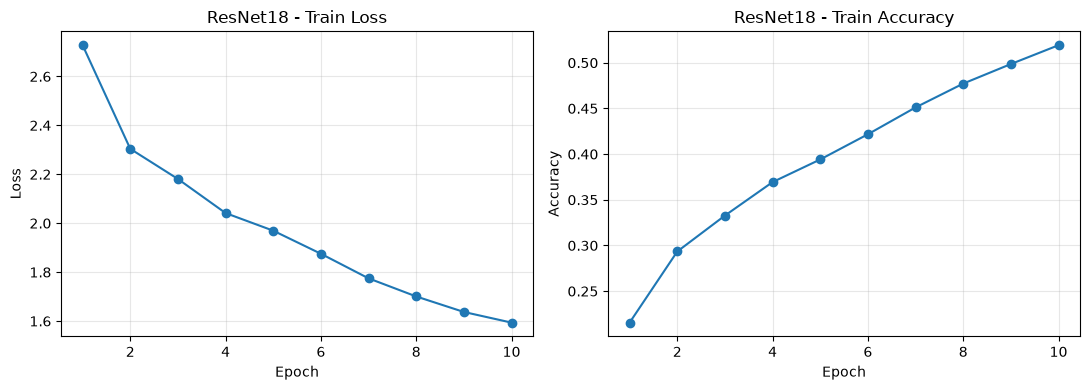

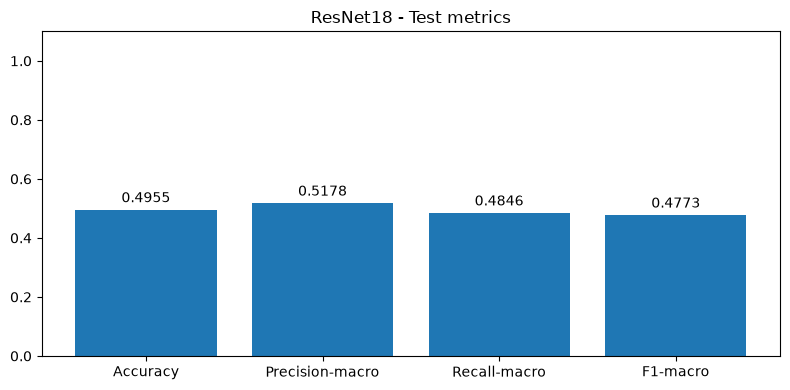

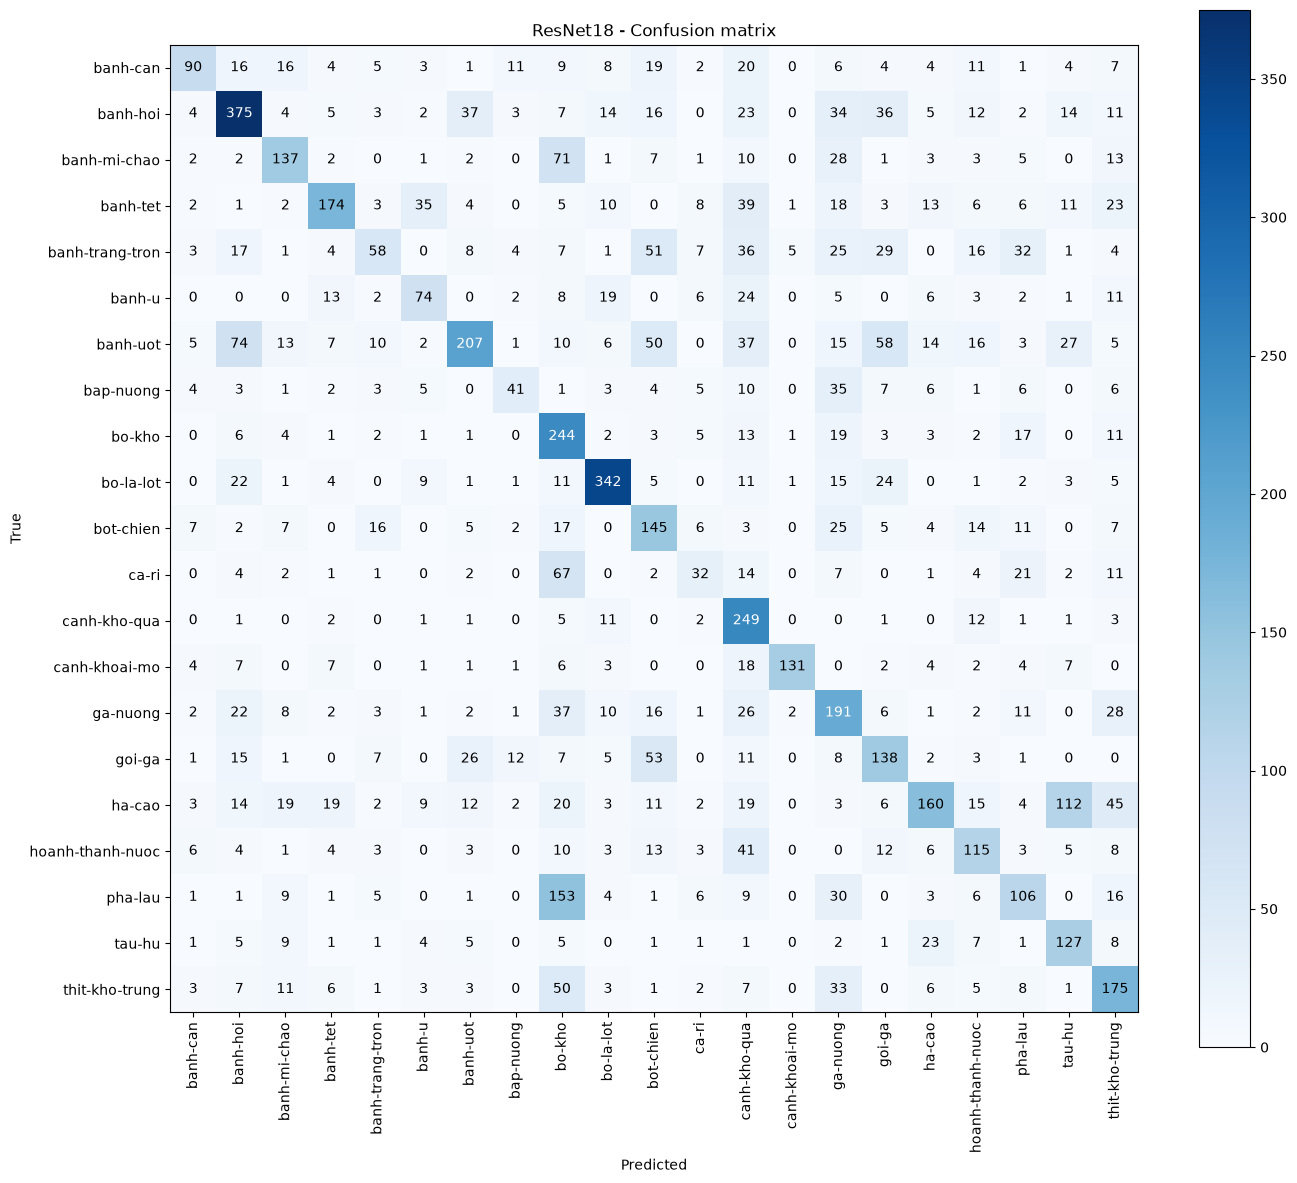

In [13]:
plot_history(history_resnet18, "ResNet18")
plot_scores(scores_resnet18, "ResNet18")
plot_confusion(food_labels, predictions_resnet18, "ResNet18", class_names=class_names)

### Bài 4: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

Dùng `timm/resnet50.a1_in1k` từ Hugging Face, thay lớp phân loại bằng 21 đầu ra và fine-tune toàn bộ tham số bằng Adam, learning rate 0.0001. Transform lấy từ cấu hình pretrained. Kaggle cần bật Internet và cài `timm` theo requirements trước khi chạy bài này.

In [14]:
resnet50 = ResNet50(num_classes=21).to(device)
train_transform, test_transform = resnet50.transforms()
food_train, food_test = VinaFoodDataset(food_dir).load(train_transform, test_transform)
food_batch_size = 32
train_loader = DataLoader(food_train, batch_size=food_batch_size, shuffle=True, pin_memory=device.type == "cuda")
test_loader = DataLoader(food_test, batch_size=food_batch_size, shuffle=False, pin_memory=device.type == "cuda")
print(f"ResNet50 - Parameters: {sum(p.numel() for p in resnet50.parameters()):,}")

ResNet50 - Parameters: 23,551,061


In [15]:
output_dir = output_root / "bai4"
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint = output_dir / "resnet50.pth"
result_path = output_dir / "results.json"
if not retrain and checkpoint.exists() and result_path.exists():
    resnet50.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    history_resnet50 = json.loads(result_path.read_text(encoding="utf-8"))["history"]
    print("Loaded saved model and training history")
else:
    history_resnet50 = fit(resnet50, train_loader, device, epochs=epochs, learning_rate=0.0001)
    torch.save(resnet50.state_dict(), checkpoint)
predictions_resnet50 = predict(resnet50, test_loader, device)
food_labels = np.asarray(food_test.targets)
scores_resnet50 = evaluate(food_labels, predictions_resnet50, num_classes=21, class_names=class_names)
results = {"config": {"epochs": len(history_resnet50), "batch_size": food_batch_size, "learning_rate": 0.0001, "seed": 42, "device": str(device)}, "classes": class_names, "history": history_resnet50, "test_metrics": scores_resnet50}
result_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"Saved: {output_dir}")

Epoch 1/10 | loss: 2.7196 | accuracy: 0.1970
Epoch 2/10 | loss: 1.7172 | accuracy: 0.5322
Epoch 3/10 | loss: 1.1219 | accuracy: 0.6666
Epoch 4/10 | loss: 0.9093 | accuracy: 0.7270
Epoch 5/10 | loss: 0.7794 | accuracy: 0.7640
Epoch 6/10 | loss: 0.6945 | accuracy: 0.7896
Epoch 7/10 | loss: 0.6514 | accuracy: 0.8032
Epoch 8/10 | loss: 0.5934 | accuracy: 0.8182
Epoch 9/10 | loss: 0.5391 | accuracy: 0.8346
Epoch 10/10 | loss: 0.5107 | accuracy: 0.8425
Accuracy: 0.8623
Class                 Precision  Recall  F1-score
banh-can              0.8555     0.9336  0.8929
banh-hoi              0.8678     0.8979  0.8826
banh-mi-chao          0.8861     0.9689  0.9256
banh-tet              0.9808     0.8407  0.9053
banh-trang-tron       0.8746     0.8803  0.8774
banh-u                0.8254     0.8864  0.8548
banh-uot              0.7953     0.7911  0.7932
bap-nuong             0.9856     0.9580  0.9716
bo-kho                0.7925     0.7456  0.7683
bo-la-lot             0.9085     0.9541  0.9308
bo

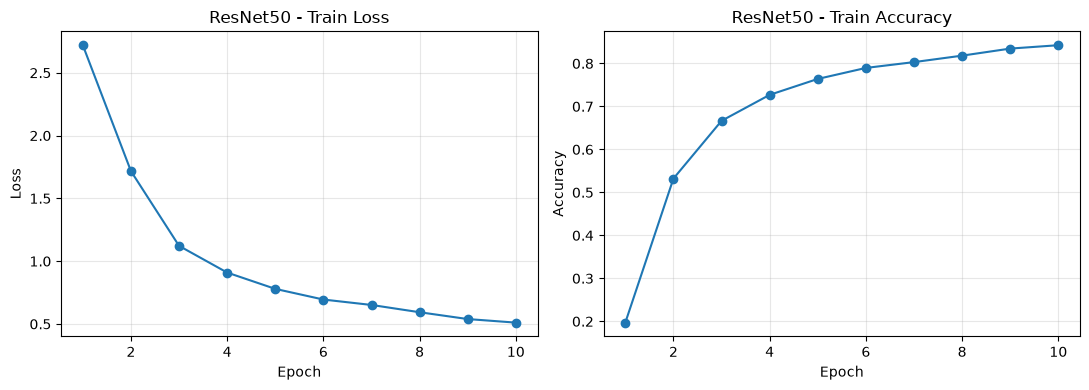

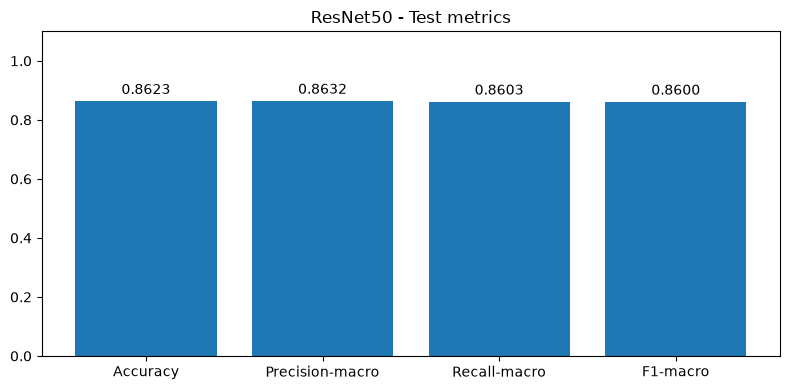

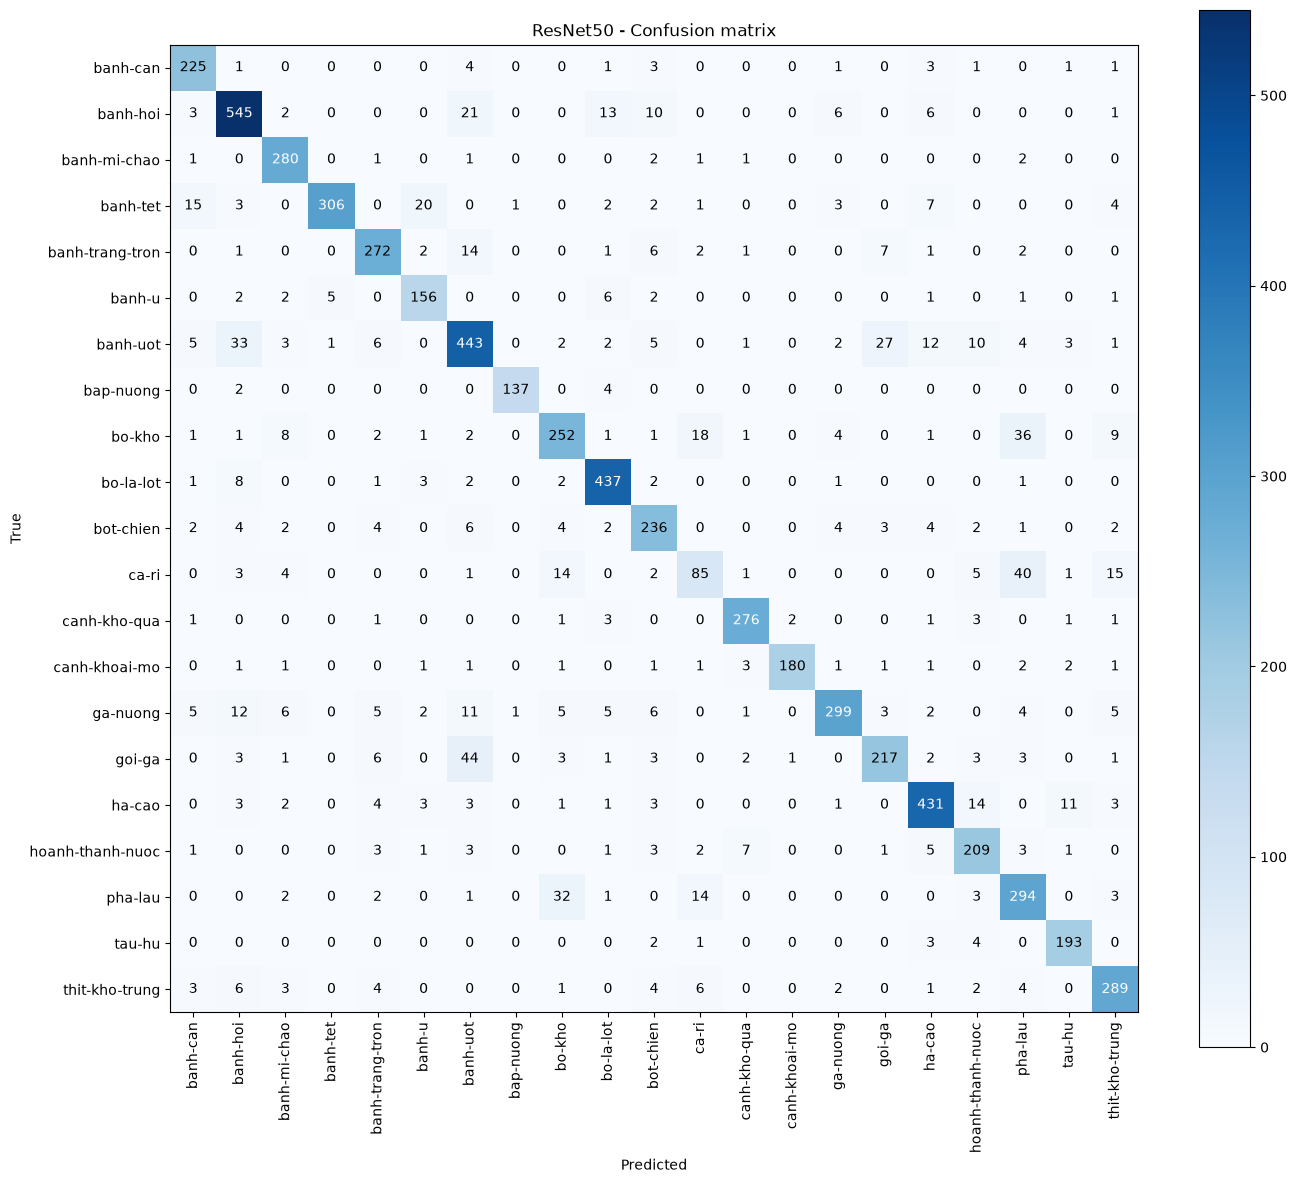

In [16]:
plot_history(history_resnet50, "ResNet50")
plot_scores(scores_resnet50, "ResNet50")
plot_confusion(food_labels, predictions_resnet50, "ResNet50", class_names=class_names)

### Kết quả chạy trên Kaggle GPU Tesla T4

Mỗi mô hình huấn luyện 10 epoch với Adam. Các độ đo bên dưới tính trên tập test; precision, recall và F1 dùng macro-average.

| Mô hình | Accuracy | Precision-macro | Recall-macro | F1-macro |
|---|---:|---:|---:|---:|
| LeNet | 98.27% | 98.26% | 98.27% | 98.26% |
| GoogLeNet | 98.93% | 98.93% | 98.91% | 98.92% |
| ResNet18 | 49.55% | 51.78% | 48.46% | 47.73% |
| ResNet50 | 86.23% | 86.32% | 86.03% | 86.00% |

LeNet và GoogLeNet đạt kết quả tốt trên MNIST. ResNet50 pretrained đạt 86,23% accuracy trên VinaFood21. ResNet-18 từ đầu đạt 49,55% accuracy; train accuracy cuối là 51,92% và loss còn giảm, cho thấy mô hình còn chưa học đủ sau 10 epoch. Cần thử huấn luyện lâu hơn và điều chỉnh learning rate trước khi kết luận mô hình đã hội tụ.

Output tiến trình lấy từ log Kaggle; đồ thị dựng lại từ history và dự đoán đã lưu của chính phiên chạy này. Đã kiểm tra lại các độ đo bằng scikit-learn và đối chiếu thứ tự nhãn test với dữ liệu local.

[Phiên chạy Kaggle](https://www.kaggle.com/code/quands/dl-lab02-four-models-gpu)